# Task 2 — Ethereum Active Addresses

## Analytical question

**How many unique Ethereum addresses were active on each day during the 30-day period?**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**

### Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `transactions`
- **SQL query:** `sql/02_active_addresses.sql`

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The first and last calendar dates are partial days because the window starts and ends at 10:01:35 UTC.

## 1. Define Active Address

For this analysis, an **active address** is a unique non-null Ethereum address that appears as either:

- `from_address` — sender of a transaction
- `to_address` — recipient of a transaction

An address is counted once per day even if it participates in many transactions that day.

### Important interpretation

**Active addresses are not the same as unique users.**

One person can control multiple addresses, and one address can be controlled or used by multiple entities. The metric measures on-chain address activity, not people or users.

For contract-creation transactions, `to_address` can be null. Null addresses are excluded from the active-address count.

In [141]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## 2. Load the analytical dataset

The large-scale distinct-address calculation is performed in BigQuery.

The BigQuery result should be exported as:

`data/processed/daily_active_addresses.csv`

Only the aggregated daily result is brought into Pandas.

In [142]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/daily_active_addresses.csv"
)
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,active_addresses
0,2026-08-24,"421,690"
1,2026-08-25,"672,803"
2,2026-08-26,"612,723"
3,2026-08-27,"645,948"
4,2026-08-28,"616,346"


## 3. Validate the analytical dataset

Check:

- number of rows
- column types
- missing values
- duplicate dates
- whether the expected 31 calendar dates are present

In [143]:
df.shape

(31, 2)

In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              31 non-null     datetime64[ns]
 1   active_addresses  31 non-null     int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 628.0 bytes


In [145]:
df.isna().sum()

date               0
active_addresses   0
dtype: int64

In [146]:
df["date"].duplicated().sum()

np.int64(0)

## 4. Identify partial boundary days

Because the analysis window begins and ends at 10:01:35 UTC, August 24 and September 23 are partial calendar days.

They should not be compared directly with the 29 complete days.

In [147]:
# The two partial days
first_day = df["date"].min()
last_day = df["date"].max()

# keep only complete days
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)]
complete_days.shape

(29, 2)

In [148]:
# .copy() creates an independent DataFrame that we can safely modify.
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)].copy()

## 5. Daily active-address baseline

Calculate the mean and median number of active addresses across the 29 complete days.

In [149]:
average_daily_active_addresses = complete_days["active_addresses"].mean()
median_daily_active_addresses = complete_days["active_addresses"].median()

average_daily_active_addresses, median_daily_active_addresses

(np.float64(635690.448275862), np.float64(645948.0))

## 6. Highest and lowest active-address days

In [150]:
highest_day = complete_days.loc[
    complete_days["active_addresses"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["active_addresses"].idxmin()
]

highest_day, lowest_day

(date                2026-09-10 00:00:00
 active_addresses                 829303
 Name: 17, dtype: object,
 date                2026-09-13 00:00:00
 active_addresses                 454329
 Name: 20, dtype: object)

## 7. Active-address change over the complete-day window

Compare the first and last complete days rather than the two partial boundary dates.

In [151]:
first_complete_day = complete_days.iloc[0]
last_complete_day = complete_days.iloc[-1]

percentage_change = (
    (last_complete_day["active_addresses"] - first_complete_day["active_addresses"])
    / first_complete_day["active_addresses"]
) * 100

first_complete_day, last_complete_day, percentage_change

(date                2026-08-25 00:00:00
 active_addresses                 672803
 Name: 1, dtype: object,
 date                2026-09-22 00:00:00
 active_addresses                 731146
 Name: 29, dtype: object,
 np.float64(8.671631963591125))

## 8. Visualize daily active addresses

A line chart is appropriate because the metric is a daily time series.

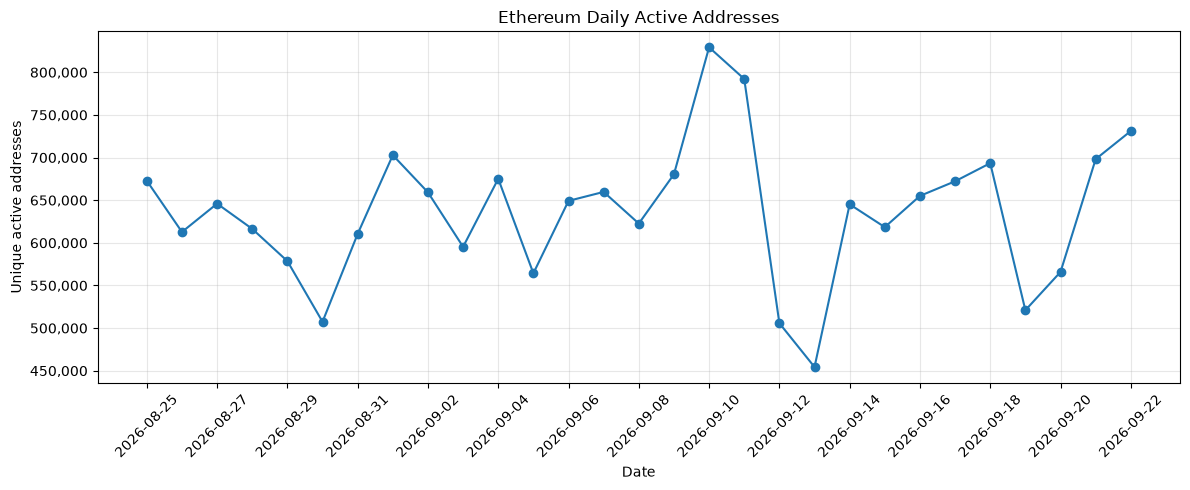

In [152]:
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(12, 5))

plt.plot(
    complete_days["date"],
    complete_days["active_addresses"],
    marker="o"
)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Show every 2nd date
ax.set_xticks(complete_days["date"][::2])

plt.title("Ethereum Daily Active Addresses")
plt.xlabel("Date")
plt.ylabel("Unique active addresses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)

plt.show()

## 9. Seven-day rolling average

Use a 7-day rolling average to distinguish short-term fluctuations from the broader movement in address activity.

In [153]:
complete_days["rolling_7d"] = (
    complete_days["active_addresses"]
    .rolling(window=7)
    .mean()
)

complete_days[["date", "active_addresses", "rolling_7d"]].tail(10)

,date,active_addresses,rolling_7d
20,2026-09-13,"454,329","649,193.43"
21,2026-09-14,"645,181","647,116.14"
22,2026-09-15,"618,404","646,515.43"
23,2026-09-16,"655,047","642,891.00"
24,2026-09-17,"672,198","620,447.43"
25,2026-09-18,"693,423","606,334.86"
26,2026-09-19,"520,970","608,507.43"
27,2026-09-20,"565,853","624,439.43"
28,2026-09-21,"698,140","632,005.00"
29,2026-09-22,"731,146","648,111.00"


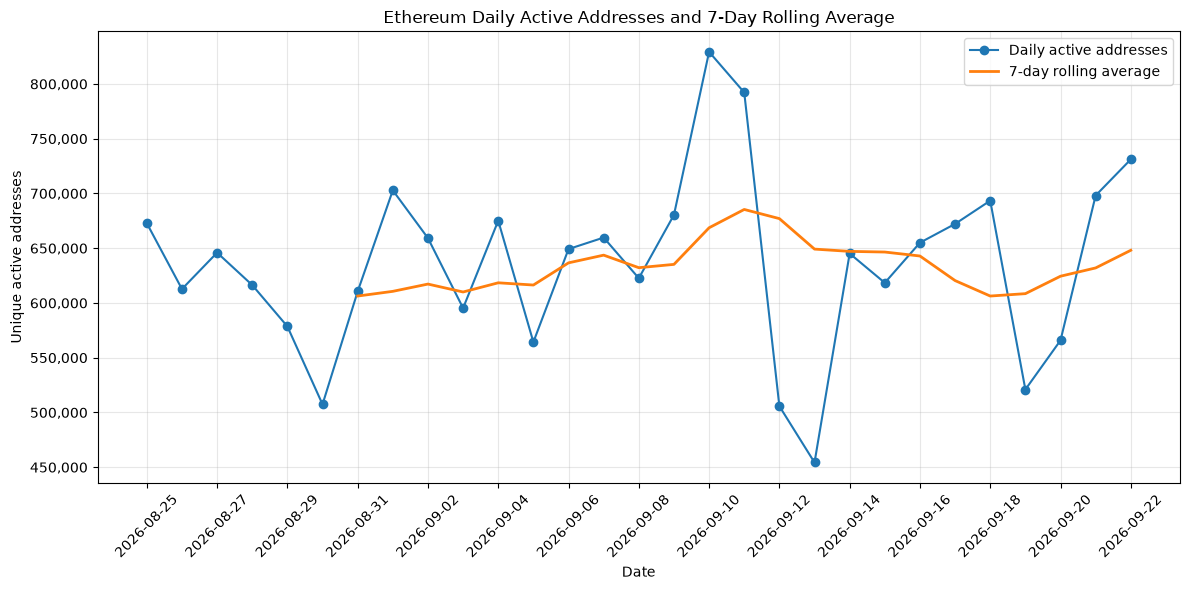

In [154]:
fig, ax = plt.subplots(figsize=(12, 6))

plt.plot(
    complete_days["date"],
    complete_days["active_addresses"],
    marker="o",
    label="Daily active addresses"
)

plt.plot(
    complete_days["date"],
    complete_days["rolling_7d"],
    linewidth=2,
    label="7-day rolling average"
)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Show every 2nd date
ax.set_xticks(complete_days["date"][::2])

plt.title("Ethereum Daily Active Addresses and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Unique active addresses")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.grid(alpha=0.3)

plt.show()

## Plotly Visualization


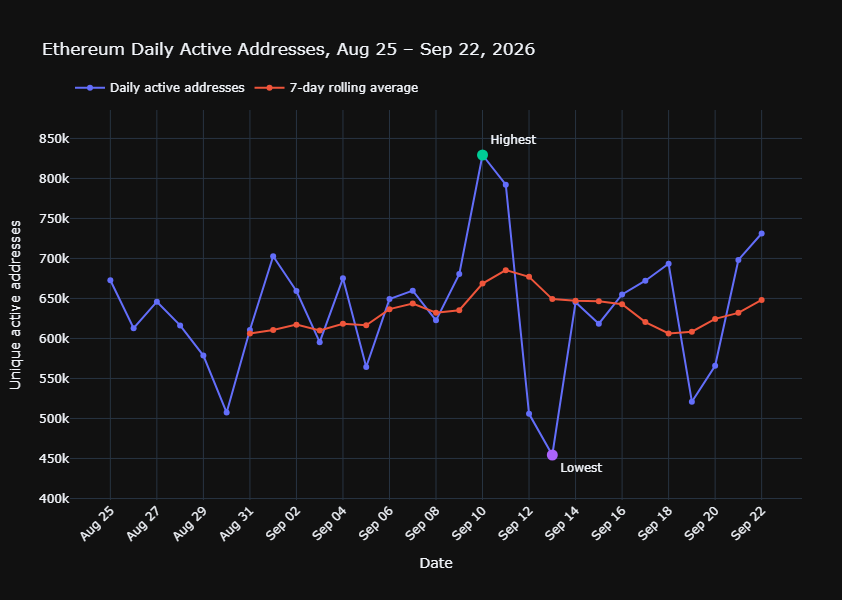

In [155]:
import plotly.express as px


# Prepare data for visualization
plot_df = complete_days[
    ["date", "active_addresses", "rolling_7d"]
].copy()

plot_df = plot_df.rename(
    columns={
        "active_addresses": "Daily active addresses",
        "rolling_7d": "7-day rolling average"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="active_addresses"
)


# Identify highest and lowest activity days
highest_day = complete_days.loc[
    complete_days["active_addresses"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["active_addresses"].idxmin()
]


# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="active_addresses",
    color="metric",
    title="Ethereum Daily Active Addresses, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "active_addresses": "Active addresses",
        "metric": ""
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Unique active addresses",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format line markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:,.0f} addresses"
        "<extra></extra>"
    )
)


# Add highest activity marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["active_addresses"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.0f} active addresses"
        "<extra></extra>"
    )
)


# Add lowest activity marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["active_addresses"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.0f} active addresses"
        "<extra></extra>"
    )
)


# Add padding to the y-axis so annotations are not clipped
y_min = complete_days["active_addresses"].min()
y_max = complete_days["active_addresses"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)


# Display the chart
fig.show()

## 10. Quantify variability

Use standard deviation and coefficient of variation to quantify how much daily active-address counts vary around their mean.

In [156]:
daily_std = complete_days["active_addresses"].std()

daily_cv = (
    daily_std / complete_days["active_addresses"].mean()
) * 100

daily_std, daily_cv

(np.float64(81777.19706250035), np.float64(12.864311125689998))

## 10. Finding | Evidence | Meaning

### Finding

Ethereum's daily active-address activity showed noticeable day-to-day variation, while remaining within a relatively consistent range across the 29 complete days. Activity increased from the beginning to the end of the comparable period, with a pronounced low on September 13 and a high on September 10.

### Evidence

- **Mean:** 635,690 active addresses/day
- **Median:** 645,948
- **Highest:** September 10 — **829,303**
- **Lowest:** September 13 — **454,329**
- **First complete day:** August 25 — **672,803**
- **Last complete day:** September 22 — **731,146**
- **First-to-last change:** **+8.67%**
- **Standard deviation:** 81,777
- **Coefficient of variation:** **12.86%**

### Meaning

The data indicates that **Ethereum's on-chain address activity fluctuated materially during the period**, with the comparable-period endpoint showing a higher active-address count than the beginning. The September 13 low and September 10 high demonstrate that daily address participation could change substantially from one day to another.

This metric measures **unique addresses involved in transactions**, not unique people or users. Therefore, the results alone should not be interpreted as a direct measure of user growth or adoption.


## Limitations

- The analysis covers a **30-day period**, so the observed patterns do not establish longer-term trends in Ethereum address activity.

- **Active addresses are not equivalent to unique users.** One person may control multiple addresses, while an address may be used by multiple entities. The metric measures on-chain address activity rather than individual user participation.

- The **first and last calendar dates are partial days** because the analysis window begins and ends at 10:01:35 UTC. These boundary dates were therefore excluded from comparable daily analysis.

- The analysis identifies **patterns and fluctuations in active-address activity but does not establish their causes**. Additional data and analysis would be required to explain why activity increased or declined on particular days.